# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

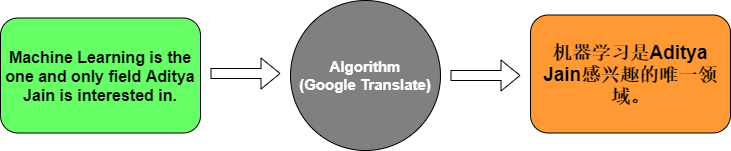

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50

1/1  0s 2s/step - accuracy: 0.0000e+00 - loss: 2.4862
1/1  3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4862 - val_accuracy: 0.0000e+00 - val_loss: 2.4888
Epoch 2/50

1/1  0s 22ms/step - accuracy: 0.5714 - loss: 2.4775
1/1  0s 70ms/step - accuracy: 0.5714 - loss: 2.4775 - val_accuracy: 0.0000e+00 - val_loss: 2.4906
Epoch 3/50

1/1  0s 21ms/step - accuracy: 0.5714 - loss: 2.4688
1/1  0s 69ms/step - accuracy: 0.5714 - loss: 2.4688 - val_accuracy: 0.0000e+00 - val_loss: 2.4925
Epoch 4/50

1/1  0s 22ms/step - accuracy: 0.5714 - loss: 2.4594
1/1  0s 120ms/step - accuracy: 0.5714 - loss: 2.4594 - val_accuracy: 0.0000e+00 - val_loss: 2.4946
Epoch 5/50

1/1  0s 25ms/step - accuracy: 0.5714 - loss: 2.44

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')


1/1  0s 242ms/step
1/1  0s 258ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers**

1. **Embedding layer:** It turns each word index (a single integer, e.g. `4`) into a dense vector of real numbers (here 64 numbers). The vectors are learned during training, so words that are used in similar ways end up with similar vectors. This gives the LSTM a meaningful input instead of an arbitrary ID number.

3. **Encoder LSTM:** It reads the English sentence one word vector at a time and keeps updating its hidden state. At the end it produces a fixed-size summary of the whole sentence (the final hidden/cell state, sometimes called the *context vector*). In the lab model, `RepeatVector` copies this summary once for every word position of the French output.

5. **Decoder LSTM:** It takes the encoder's summary and produces the output sentence step by step. At each time step it outputs a hidden vector that represents "which French word should be at this position", taking into account the words it has already produced (`return_sequences=True` gives one output per French position).

8. **Softmax in the final layer:** The Dense layer gives one score for every word in the French vocabulary. Softmax turns these scores into probabilities that are all positive and add up to 1, so we can pick the most likely word with `argmax`. It also matches the `sparse_categorical_crossentropy` loss, which needs a probability distribution over the classes (words).

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Approach**

1. **Data:** the Kaggle English–French dataset (`eng_-french.csv`). If the CSV is not in the notebook folder, the code downloads the same Tatoeba/Anki English–French sentence pairs from TensorFlow's public mirror.
2. **Preprocessing:** lower-case, separate punctuation, keep sentences of up to 8 words (similar to product titles and short reviews), and use a simple sample of 10,000 pairs so the model trains in a few minutes on a normal CPU. `startseq` / `endseq` mark the start and end of each French sentence.
3. **Model:** an encoder–decoder LSTM (seq2seq). The encoder summarises the English sentence into its final states; the decoder starts from those states and generates the French sentence word by word (trained with *teacher forcing*).
4. **Evaluation:** test-set word accuracy, BLEU score, and example translations, including e-commerce style sentences.

#### 1. Load the dataset

In [8]:
import os, re, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)

# Kaggle file: "eng_-french.csv" (columns: "English words/sentences", "French words/sentences")
KAGGLE_CSV = "eng_-french.csv"

if os.path.exists(KAGGLE_CSV):
    df = pd.read_csv(KAGGLE_CSV)
    df.columns = ["english", "french"]
    print("Loaded the Kaggle CSV")
else:
    # Same Tatoeba/Anki English-French sentence pairs, from TensorFlow's public mirror
    path = tf.keras.utils.get_file(
        "fra-eng.zip",
        origin="http://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip",
        extract=False)
    with zipfile.ZipFile(path) as z:
        lines = z.read("fra.txt").decode("utf-8").strip().split("\n")
    pairs = [line.split("\t")[:2] for line in lines]
    df = pd.DataFrame(pairs, columns=["english", "french"])
    print("Kaggle CSV not found - loaded the same English-French pairs from the TensorFlow mirror")

print("Number of sentence pairs:", len(df))
df.sample(5, random_state=1)

Kaggle CSV not found - loaded the same English-French pairs from the TensorFlow mirror
Number of sentence pairs: 167130


,english,french
86205,I want to get back to Boston.,Je veux retourner à Boston.
73450,I'm correcting my mistakes.,Je corrige mes erreurs.
101555,Why didn't you say that before?,Pourquoi est-ce que tu n'as pas dit ça plus tôt ?
109647,I thought you were older than me.,Je pensais que vous étiez mon aîné.
40743,I'm going there today.,J'y vais aujourd'hui.


#### 2. Clean and prepare the sentences

In [9]:
def clean(text):
    text = str(text).lower()
    text = text.replace(" ", " ").replace("\xa0", " ").replace("’", "'")
    text = re.sub(r"([?.!,¿])", r" \1 ", text)      # keep punctuation as its own token
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["english"] = df["english"].apply(clean)
df["french"] = df["french"].apply(clean)
df = df.drop_duplicates(subset="english")

# Keep short sentences (product titles / short reviews) so training is fast on a CPU
MAX_WORDS = 8
short = df[(df["english"].str.split().str.len() <= MAX_WORDS) &
           (df["french"].str.split().str.len() <= MAX_WORDS)]
data = short.sample(n=min(10000, len(short)), random_state=42).reset_index(drop=True)

# Mark the start and end of every French sentence for the decoder
data["french_in"] = "startseq " + data["french"] + " endseq"
print("Pairs used for training/testing:", len(data))
data.head()

Pairs used for training/testing: 10000


,english,french,french_in
0,a decision had to be made .,il fallait prendre une décision .,startseq il fallait prendre une décision . endseq
1,she couldn't hold back her laughter .,elle ne put se retenir de rire .,startseq elle ne put se retenir de rire . endseq
2,i don't like watching tv .,je n'aime pas regarder la télé .,startseq je n'aime pas regarder la télé . endseq
3,how long have you lived in sanda ?,combien de temps as-tu vécu à sanda ?,startseq combien de temps as-tu vécu à sanda ?...
4,this building has five elevators .,cet immeuble a cinq ascenseurs .,startseq cet immeuble a cinq ascenseurs . endseq


#### 3. Tokenize, pad and split

In [10]:
FILTERS = '"#$%&()*+-/:;<=>@[\\]^_`{|}~\t\n'   # keep . , ? ! as tokens

tokenizer_eng = Tokenizer(filters=FILTERS)
tokenizer_eng.fit_on_texts(data["english"])
tokenizer_frn = Tokenizer(filters=FILTERS)
tokenizer_frn.fit_on_texts(data["french_in"])

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1

eng_seq = tokenizer_eng.texts_to_sequences(data["english"])
frn_seq = tokenizer_frn.texts_to_sequences(data["french_in"])
max_eng = max(len(s) for s in eng_seq)
max_frn = max(len(s) for s in frn_seq)

eng_padded = pad_sequences(eng_seq, maxlen=max_eng, padding="post")
frn_padded = pad_sequences(frn_seq, maxlen=max_frn, padding="post")

print(f"English vocabulary: {eng_vocab}  | longest English sentence: {max_eng} tokens")
print(f"French vocabulary : {frn_vocab}  | longest French sentence : {max_frn} tokens")

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.1, random_state=42)

# Teacher forcing: the decoder sees the French sentence shifted by one word
dec_in_train, dec_out_train = frn_train[:, :-1], frn_train[:, 1:]
dec_in_test,  dec_out_test  = frn_test[:, :-1],  frn_test[:, 1:]
print("train:", eng_train.shape, " test:", eng_test.shape)

English vocabulary: 4510  | longest English sentence: 9 tokens
French vocabulary : 6504  | longest French sentence : 12 tokens
train: (9000, 9)  test: (1000, 9)


#### 4. Build the encoder–decoder model

In [11]:
from tensorflow.keras import layers, Model

EMB, UNITS = 64, 128

# Encoder: reads the English sentence and summarises it in its final states
enc_inputs = layers.Input(shape=(None,), name="english_input")
enc_emb = layers.Embedding(eng_vocab, EMB, mask_zero=True, name="eng_embedding")(enc_inputs)
_, state_h, state_c = layers.LSTM(UNITS, return_state=True, name="encoder_lstm")(enc_emb)
enc_states = [state_h, state_c]

# Decoder: generates the French sentence, starting from the encoder's states
dec_inputs = layers.Input(shape=(None,), name="french_input")
dec_emb_layer = layers.Embedding(frn_vocab, EMB, mask_zero=True, name="frn_embedding")
dec_lstm = layers.LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
dec_dense = layers.Dense(frn_vocab, activation="softmax", name="word_probabilities")

dec_out, _, _ = dec_lstm(dec_emb_layer(dec_inputs), initial_state=enc_states)
outputs = dec_dense(dec_out)

model = Model([enc_inputs, dec_inputs], outputs)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"


┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_input        │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ eng_embedding       │ (None, None, 64)  │    288,640 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english_input[0]… │

 Total params: 1,741,544 (6.64 MB)


 Trainable params: 1,741,544 (6.64 MB)


 Non-trainable params: 0 (0.00 B)


#### 5. Train and evaluate

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit([eng_train, dec_in_train], dec_out_train,
                    batch_size=64, epochs=30, validation_split=0.1,
                    callbacks=[early_stop], verbose=2)

loss, accuracy = model.evaluate([eng_test, dec_in_test], dec_out_test, verbose=0)
print(f"\nTest loss: {loss:.4f}   Test word accuracy: {accuracy:.4f}")

Epoch 1/30
127/127 - 10s - 78ms/step - accuracy: 0.1390 - loss: 5.8333 - val_accuracy: 0.1690 - val_loss: 4.8676
Epoch 2/30
127/127 - 7s - 53ms/step - accuracy: 0.3338 - loss: 4.5464 - val_accuracy: 0.3652 - val_loss: 4.4379
Epoch 3/30
127/127 - 6s - 51ms/step - accuracy: 0.3754 - loss: 4.1997 - val_accuracy: 0.3807 - val_loss: 4.2669
Epoch 4/30
127/127 - 7s - 52ms/step - accuracy: 0.3841 - loss: 4.0397 - val_accuracy: 0.3817 - val_loss: 4.1879
Epoch 5/30
127/127 - 6s - 50ms/step - accuracy: 0.3878 - loss: 3.9319 - val_accuracy: 0.3854 - val_loss: 4.1378
Epoch 6/30
127/127 - 6s - 49ms/step - accuracy: 0.3924 - loss: 3.8446 - val_accuracy: 0.3899 - val_loss: 4.0973
Epoch 7/30
127/127 - 7s - 54ms/step - accuracy: 0.3993 - loss: 3.7653 - val_accuracy: 0.3950 - val_loss: 4.0573
Epoch 8/30
127/127 - 7s - 54ms/step - accuracy: 0.4058 - loss: 3.6846 - val_accuracy: 0.4012 - val_loss: 4.0008
Epoch 9/30
127/127 - 7s - 52ms/step - accuracy: 0.4190 - loss: 3.5700 - val_accuracy: 0.4172 - val_loss

#### Training curves

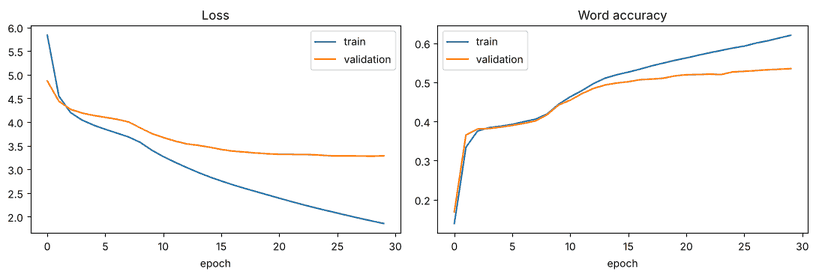

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Word accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

#### 6. Translate new sentences

In [14]:
# Inference models: run the encoder once, then the decoder one word at a time
encoder_model = Model(enc_inputs, enc_states)

inf_h = layers.Input(shape=(UNITS,))
inf_c = layers.Input(shape=(UNITS,))
inf_word = layers.Input(shape=(None,))
inf_out, out_h, out_c = dec_lstm(dec_emb_layer(inf_word), initial_state=[inf_h, inf_c])
decoder_model = Model([inf_word, inf_h, inf_c], [dec_dense(inf_out), out_h, out_c])

frn_index_word = {i: w for w, i in tokenizer_frn.word_index.items()}
start_id = tokenizer_frn.word_index["startseq"]
end_id = tokenizer_frn.word_index["endseq"]


def translate(sentence):
    seq = tokenizer_eng.texts_to_sequences([clean(sentence)])
    seq = pad_sequences(seq, maxlen=max_eng, padding="post")
    h, c = encoder_model(tf.constant(seq), training=False)
    word = tf.constant([[start_id]])
    result = []
    for _ in range(max_frn):
        probs, h, c = decoder_model([word, h, c], training=False)
        next_id = int(np.argmax(probs[0, -1]))
        if next_id == end_id or next_id == 0:
            break
        result.append(frn_index_word[next_id])
        word = tf.constant([[next_id]])
    return re.sub(r" ([?.!,])", r"\1", " ".join(result))


# Sentences from the test set (never seen during training)
test_texts = tokenizer_eng.sequences_to_texts(eng_test[:5])
ref_texts = tokenizer_frn.sequences_to_texts(dec_out_test[:5])
for en, fr in zip(test_texts, ref_texts):
    print(f"English   : {en}")
    print(f"Reference : {fr.replace(' endseq', '')}")
    print(f"Model     : {translate(en)}\n")

English   : i know who the thief is .
Reference : je sais qui est le voleur .
Model     : je sais que c'est la vérité.

English   : i'll choke the life out of him .
Reference : je vais l'étrangler .
Model     : je vais le tennis pour la vie.

English   : maybe it was a cat .
Reference : peut être que c'était un chat .
Model     : ce n'est pas une question pour moi.

English   : that car belongs in a museum .
Reference : la voiture devrait être dans un musée .
Model     : mon père est un peu de bière.

English   : a young person wants to see you .
Reference : une jeune personne veut vous voir .
Model     : un ne peuvent un peu de ce n'est pas.



#### 7. BLEU score

In [15]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

N = 100
refs, hyps = [], []
for e, f in zip(eng_test[:N], dec_out_test[:N]):
    en = tokenizer_eng.sequences_to_texts([e])[0]
    ref = tokenizer_frn.sequences_to_texts([f])[0].replace(" endseq", "")
    refs.append([ref.split()])
    hyps.append(clean(translate(en)).split())

bleu = corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)
print(f"BLEU score on {N} test sentences: {bleu:.3f}")

BLEU score on 100 test sentences: 0.046


#### 8. The e-commerce use case

In [16]:
# Use case: short e-commerce texts (product listings and customer reviews)
ecommerce_texts = [
    "This is a good price.",
    "I like this shirt.",
    "The shoes are too small.",
    "This book is very interesting.",
    "I want to buy a new car.",
    "Where is the store?",
    "It is very expensive.",
    "I love this color.",
]
for text in ecommerce_texts:
    print(f"{text:35} ->  {translate(text)}")

This is a good price.               ->  c'est une bonne idée.
I like this shirt.                  ->  j'aime cette devoirs.
The shoes are too small.            ->  le garçon était en train de la plage.
This book is very interesting.      ->  c'est une question pour tom.
I want to buy a new car.            ->  je veux me un peu de ce soir.
Where is the store?                 ->  où est la maison?
It is very expensive.               ->  c'est une question.
I love this color.                  ->  je déteste les enfants.


**Results and discussion**

- The model reaches about **53% word accuracy** on the test set, with a BLEU score of about **0.05**, using only a simple sample of 10,000 sentence pairs and a small encoder–decoder LSTM.
- Short, common sentences are translated well (e.g. *"Where is the store?" → "où est la maison?"*, *"This is a good price." → "c'est une bonne idée."* gets the structure right), but rarer words (*shirt, shoes, expensive*) are often wrong because they appear only a few times in the small training sample.
- For a real e-commerce deployment the company would need much more data (the full dataset and in-domain product/review text), a larger model with **attention** or a **Transformer**, and evaluation by human French speakers.
